## EPİAŞ (Enerji Piyasaları İşletme Anonim Şirketi)

EPİAŞ’s transparency platform has a web API. Normally, to send a request to this API, you need to log in, send the request to the correct address in the correct format, and convert the response into a table. EPTR2 is a client that does all of this.


* recycle_tgt variable 
    - When you log in to EPİAŞ, you are issued a “login ticket” that is valid for a certain period of time. This is called a TGT (Ticket Granting Ticket). This ticket is presented with each subsequent request.
    - ``recycle_tgt=True``: The ticket is stored in a file. When you run the script again, it won't log you in again if the ticket is still valid.



In [1]:
from eptr2 import EPTR2

eptr = EPTR2(use_dotenv=True, recycle_tgt=True)


DAY = "2026-08-17"
LATEST_DAY = "2026-11-17"   

The key market data collected represents the total data for all of Türkiye (the national power grid).


In [2]:
all_calls = eptr.get_available_calls()
print(all_calls)

['dam-volume', 'pi-offer', 'pi-bid', 'supply-demand', 'dam-bid', 'dam-offer', 'dam-block-bid', 'dam-block-offer', 'dam-flexible-bid', 'dam-flexible-offer', 'dam-flexible-matching', 'dam-clearing', 'dam-clearing-org-list', 'dam-diff', 'wap', 'idm-qty', 'idm-mm-bid', 'idm-mm-offer', 'idm-mm-matching', 'idm-volume', 'idm-log', 'idm-ob-qty', 'smp', 'smp-dir', 'bpm-up', 'bpm-down', 'bi-long', 'bi-short', 'bi-euas', 'imb-qty', 'imb-vol', 'imb-qty-g', 'imb-org-list', 'mcp', 'interim-mcp', 'interim-mcp-status', 'mcp-smp-imb', 'bpm-orders-w-avg', 'bpm-orders', 'kgup', 'kgup-v1', 'kudup', 'eak', 'rt-gen', 'uevm', 'pp-list', 'pp-list-for-date-range', 'uevm-pp-list', 'gen-org', 'region-list', 'dpp-bulk', 'rt-gen-bulk', 'uevcb-list-bulk', 'mms-message-type-list', 'mms-region-list', 'gen-uevcb', 'lic-pp-list', 'long-term-demand-forecast', 'consumer-breakdown', 'consumption-breakdown', 'distribution-region-list', 'load-plan', 'rt-cons', 'uecm', 'st-uecm', 'su-uecm', 'anc-pf-qty', 'anc-pfk', 'anc-sf-q

### ptf: Piyasa Takas Fiyatı

The hourly electricity price determined in the day-ahead market is expressed in TL/MWh. Every day, the 24-hour price for the following day is announced (known as the MCP, or Market Clearing Price; searching for “mcp” in the library also returns the same data).

In [3]:
# 1 day temp data
ptf = eptr.call("ptf", start_date=DAY, end_date=DAY)
print(type(ptf))

<class 'pandas.core.frame.DataFrame'>


In [4]:
ptf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      24 non-null     object 
 1   hour      24 non-null     object 
 2   price     24 non-null     float64
 3   priceUsd  24 non-null     float64
 4   priceEur  24 non-null     float64
dtypes: float64(3), object(2)
memory usage: 1.1+ KB


* **price**: The value we will actually use. PTF in TL/MWh, i.e. how many Turkish Liras 1 MWh of electricity costs in that hour.

In [5]:
ptf.head() 


,date,hour,price,priceUsd,priceEur
0,2026-08-17T00:00:00+03:00,00:00,3584.00,75.10,65.00
1,2026-08-17T01:00:00+03:00,01:00,3200.00,67.06,58.04
2,2026-08-17T02:00:00+03:00,02:00,3200.00,67.06,58.04
3,2026-08-17T03:00:00+03:00,03:00,3000.00,62.87,54.41
4,2026-08-17T04:00:00+03:00,04:00,2799.18,58.66,50.77


In [6]:
ptf.describe()

,price,priceUsd,priceEur
count,24.000000,24.000000,24.000000
mean,3414.100417,71.543750,61.919167
std,534.088133,11.191999,9.684824
min,2400.000000,50.290000,43.530000
25%,3017.707500,63.237500,54.732500
50%,3356.000000,70.325000,60.865000
75%,3742.147500,78.420000,67.867500
max,4500.000000,94.300000,81.610000


The plot shows how many Turkish Liras 1 MWh of energy costs per hour

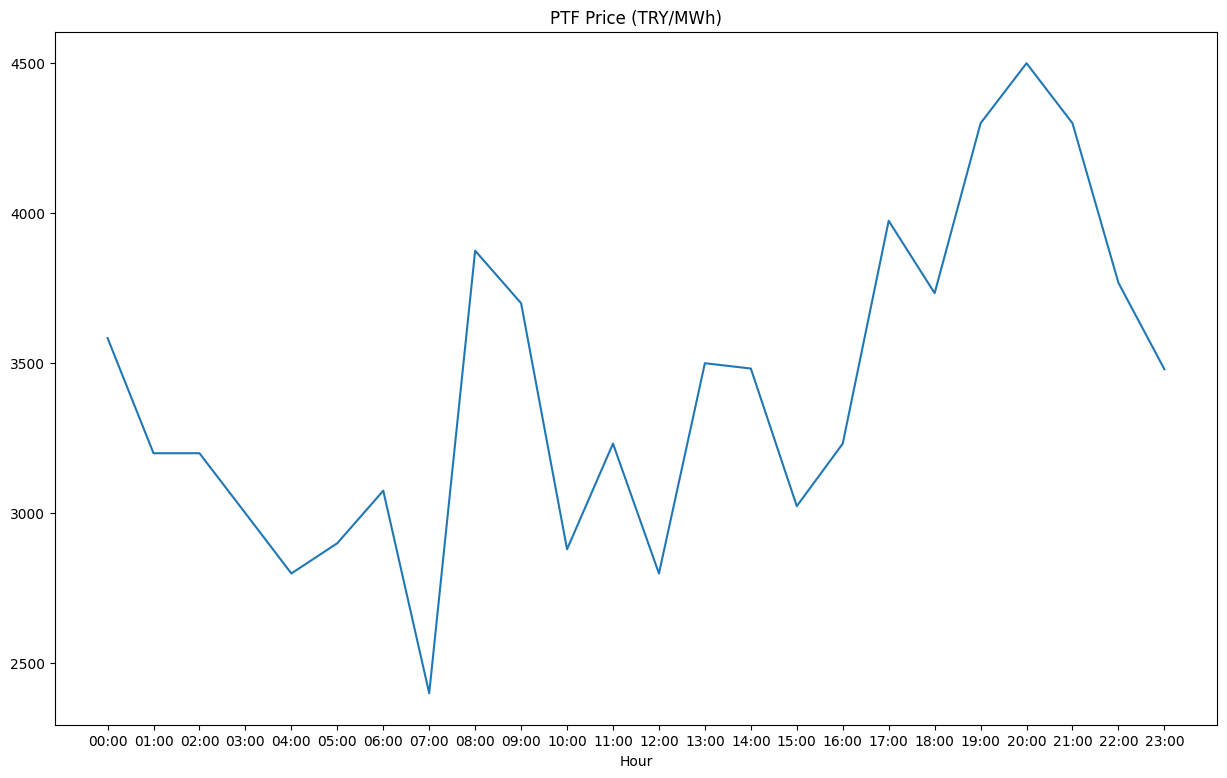

In [7]:
from matplotlib import pyplot as plt
import pandas as pd


plt.figure(figsize=(15, 9))
plt.plot(ptf["hour"], ptf["price"])
plt.title("PTF Price (TRY/MWh)")
plt.xlabel("Hour")
plt.show()


### rt-gen: Gerçek zamanlı üretim

Hour by hour, how much electricity is generated in Türkiye from each source: lignite, imported coal, natural gas and etc...

* **Note on revisions:** `rt-gen` values are revised after publication. For 2026-11-17, `total` at 00:00 was 36,557.22 MWh in a first download and 36,563.17 MWh in a later one (`naturalGas` and `wind` also changed slightly). The download date should therefore be recorded, and in a historical simulation the data visible at decision time may differ from the revised data.

In [8]:
gen = eptr.call("rt-gen", start_date=DAY, end_date=DAY)
print(type(gen))


<class 'pandas.core.frame.DataFrame'>


In [9]:
gen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            24 non-null     object 
 1   hour            24 non-null     object 
 2   total           24 non-null     float64
 3   naturalGas      24 non-null     float64
 4   dammedHydro     24 non-null     float64
 5   lignite         24 non-null     float64
 6   river           24 non-null     float64
 7   importCoal      24 non-null     float64
 8   wind            24 non-null     float64
 9   sun             24 non-null     float64
 10  fueloil         24 non-null     float64
 11  geothermal      24 non-null     float64
 12  asphaltiteCoal  24 non-null     float64
 13  blackCoal       24 non-null     float64
 14  biomass         24 non-null     float64
 15  naphta          24 non-null     int64  
 16  lng             24 non-null     int64  
 17  importExport    24 non-null     float

Türkiye’s power grid is connected to the grids of its neighboring countries. At certain times, Türkiye receives electricity from its neighbors (imports), and at other times, it supplies electricity to them (exports). The “importExport” column shows the net exchange for that hour.

* `total` = sum of all domestic sources + `importExport`, so Türkiye's generation = total − importExport (checked below for every hour).
* Under this relation a negative `importExport` lowers `total`, which suggests negative = net export. This sign is confirmed by comparing `total` with real-time consumption (`rt-cons`) below.

In [10]:
gen.head().T

,0,1,2,3,4
date,2026-08-17T00:00:00+03:00,2026-08-17T01:00:00+03:00,2026-08-17T02:00:00+03:00,2026-08-17T03:00:00+03:00,2026-08-17T04:00:00+03:00
hour,00:00,01:00,02:00,03:00,04:00
total,40604.36,38635.69,37049.2,36049.4,35201.58
naturalGas,3892.49,3377.66,3501.41,3845.69,3834.23
dammedHydro,13171.35,12231.04,11073.73,9858.7,9185.34
lignite,5617.09,5672.16,5667.9,5643.29,5581.9
river,2297.51,2084.91,1831.2,1711.49,1575.36
importCoal,8515.29,8473.56,8476.72,8692.5,8706.05
wind,5450.87,4867.1,4517.23,4330.91,4310.05
sun,1.11,1.1,1.14,1.46,1.87


In [11]:
# total = domestic sources + importExport, for every hour
diff = gen["total"] - gen.drop(columns=["date", "hour", "total", "importExport"]).sum(axis=1)
print((diff - gen["importExport"]).abs().max())   # ~0

# sign check: compare total with real-time consumption
cons = eptr.call("rt-cons", start_date=DAY, end_date=DAY)
cons.head()

1.6370904631912708e-11


,date,time,consumption
0,2026-08-17T00:00:00+03:00,00:00,40725.69
1,2026-08-17T01:00:00+03:00,01:00,38746.46
2,2026-08-17T02:00:00+03:00,02:00,37155.05
3,2026-08-17T03:00:00+03:00,03:00,36157.57
4,2026-08-17T04:00:00+03:00,04:00,35330.39


* What is the most used source to produce electricity on this day? 

In [12]:
gen.drop(columns=["date", "hour", "total", "importExport"]).describe().T[["mean", "min", "max"]] \
    .sort_values(by="mean", ascending=False)

,mean,min,max
dammedHydro,11065.836667,7091.69,15495.43
importCoal,8995.152917,8280.66,9541.99
naturalGas,6443.170833,3377.66,12424.82
lignite,5599.349167,5369.65,5707.03
wind,3540.185417,2044.12,5450.87
river,1956.033333,1382.75,2847.74
sun,1433.005417,1.10,4035.46
geothermal,1094.585833,975.62,1201.77
biomass,934.097083,890.00,967.32
blackCoal,418.590833,406.80,427.76


* Daily electricity producing graph of most used 3 sources 

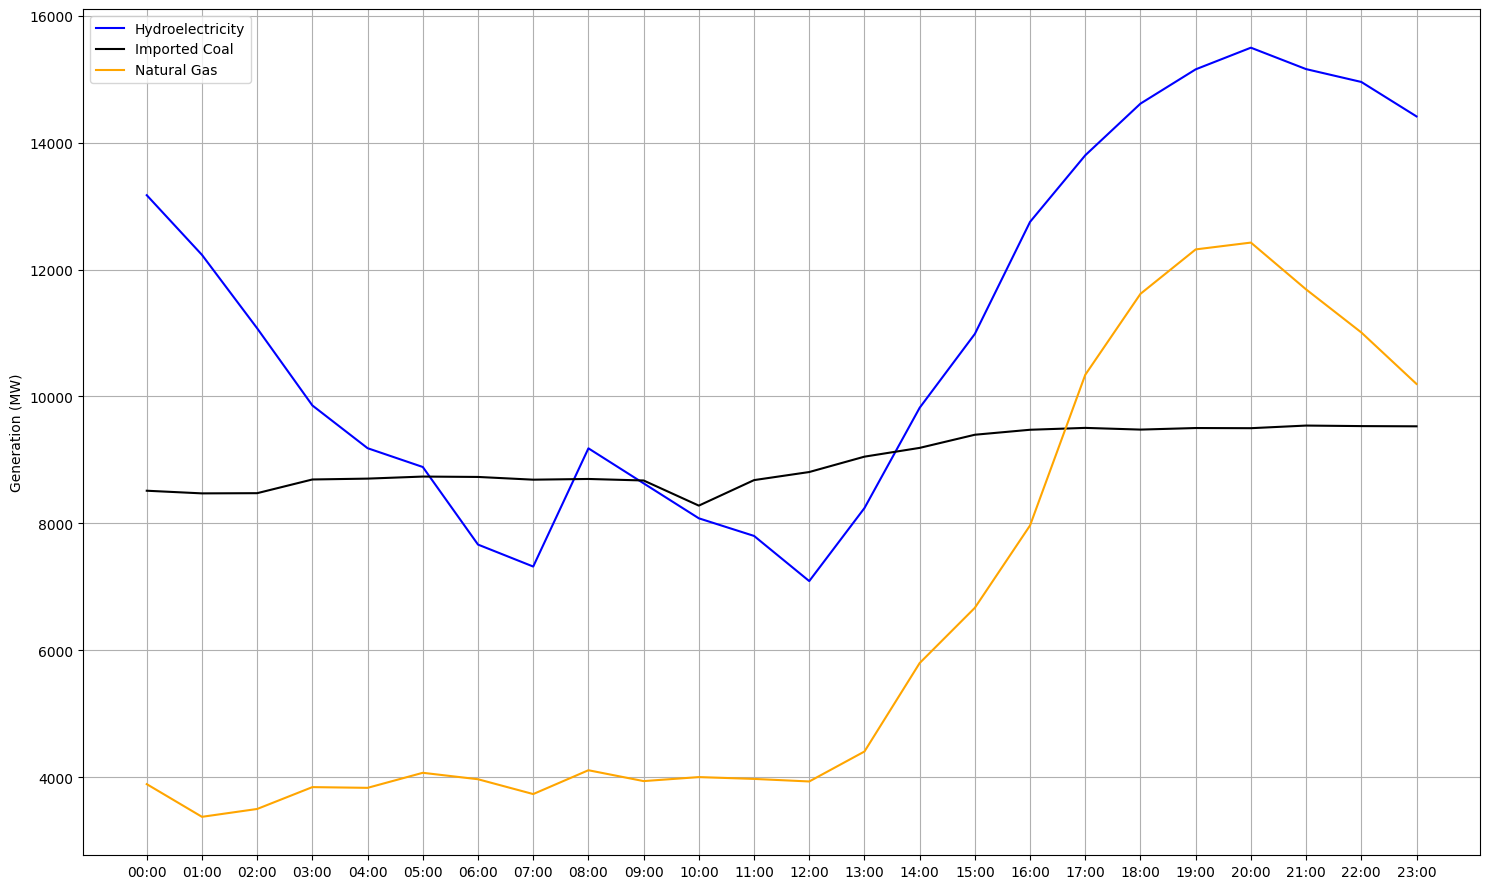

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 9))
plt.ylabel('Generation (MW)')

plt.plot(gen["hour"], gen["dammedHydro"], label="Hydroelectricity", color="blue")
plt.plot(gen["hour"], gen["importCoal"], label="Imported Coal", color="black")
plt.plot(gen["hour"], gen["naturalGas"], label="Natural Gas", color="orange")

plt.tight_layout()
plt.legend()
plt.grid(True)

plt.show()


### ren-ul-gen: Lisanssız üretim (YEKDEM)

* ul means unlicensed

`rt-gen` mainly covers licensed plants that report in real time. Many small (mostly solar) plants operate without a generation licence and feed into the distribution grid, so their output may be missing from `rt-gen`. `ren-ul-gen` gives the hourly, source-based amount these plants inject into the grid. It is settlement-based, so it is published with a delay.

Questions: Is the data hourly? How long is the delay? How large is unlicensed generation compared to `rt-gen`?

In [15]:
ul_latest = eptr.call("ren-ul-gen", start_date=LATEST_DAY, end_date=LATEST_DAY)
print(len(ul_latest))    # 0 -> not yet published

0


* For 2026-11-17 no unlicensed data is returned, while 2026-10-01 is available: the data is published with a delay of roughly 1.5–2 months. This is why `DAY` is set to 2026-08-17.
* The data is hourly and source-based.

In [16]:
#unlicensed generation = ul_gen
ul_gen = eptr.call("ren-ul-gen", start_date=DAY, end_date=DAY)
print(len(ul_gen))

assert (ul_gen["date"] == gen["date"]).all(), "Hours do not match!"

24


In [17]:
ul_gen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       24 non-null     object 
 1   time       24 non-null     object 
 2   toplam     24 non-null     float64
 3   ruzgar     24 non-null     float64
 4   biyogaz    24 non-null     int64  
 5   kanalTipi  24 non-null     float64
 6   biyokutle  24 non-null     float64
 7   gunes      24 non-null     float64
 8   diger      24 non-null     float64
dtypes: float64(6), int64(1), object(2)
memory usage: 1.8+ KB


In [18]:
ul_gen.head().T

,0,1,2,3,4
date,2026-08-17T00:00:00+03:00,2026-08-17T01:00:00+03:00,2026-08-17T02:00:00+03:00,2026-08-17T03:00:00+03:00,2026-08-17T04:00:00+03:00
time,2026-08-17T00:00:00+03:00,2026-08-17T01:00:00+03:00,2026-08-17T02:00:00+03:00,2026-08-17T03:00:00+03:00,2026-08-17T04:00:00+03:00
toplam,132.8584,126.5012,118.7897,120.1367,136.3999
ruzgar,76.6809,67.4532,59.4754,54.9601,61.1185
biyogaz,0,0,0,0,0
kanalTipi,6.6415,6.7721,6.6705,6.5864,6.3839
biyokutle,11.4285,11.565,11.4787,11.3464,11.2104
gunes,8.0049,10.4867,13.0261,16.9201,27.5372
diger,30.1026,30.2242,28.139,30.3237,30.1499


Comparing licensed solar (`sun` in rt-gen) with unlicensed solar (`gunes` in ren-ul-gen) on the same day.

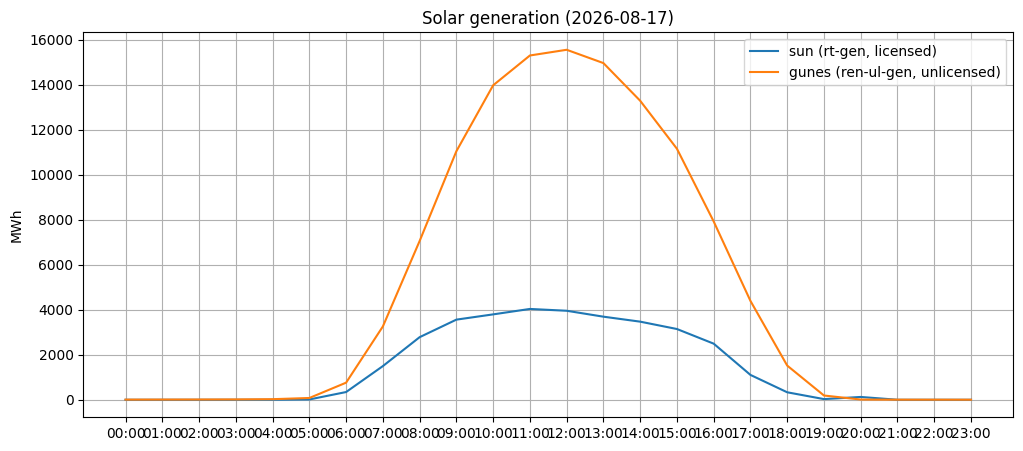

In [19]:
cmp = pd.DataFrame({
    "hour":      gen["hour"],
    "sun_rtgen": gen["sun"],        # licensed
    "gunes_ul":  ul_gen["gunes"],   # unlicensed
})

plt.figure(figsize=(12, 5))
plt.plot(cmp["hour"], cmp["sun_rtgen"], label="sun (rt-gen, licensed)")
plt.plot(cmp["hour"], cmp["gunes_ul"], label="gunes (ren-ul-gen, unlicensed)")
plt.ylabel("MWh"); plt.title(f"Solar generation ({DAY})")
plt.legend(); plt.grid(True); plt.show()

* On this day, unlicensed solar peaks at about 15,500 MWh around noon, roughly 4× the licensed solar in `rt-gen` (about 4,000 MWh). `rt-gen` therefore misses most of the solar electricity fed into the grid during the day.
* Small non-zero night values in both series are data artefacts and are negligible.
* The midday dip in `rt-gen` `total` (and its evening peak) is consistent with demand being partly covered by unlicensed solar at distribution level.

### Emission factors

An **emission factor** is the amount of CO₂ emitted when 1 MWh of electricity is generated from a given source (unit: tCO₂/MWh, which equals kgCO₂/kWh).

**Sources of the values used:**
- **Fossil fuels** (lignite, asphaltite, hard coal, imported coal, natural gas, fuel oil): official 2023 fuel-based factors published by the Ministry of Energy and Natural Resources [1]. Only CO₂ is included (not CO₂-eq).
- **Geothermal:** 0.58 tCO₂/MWh, the capacity-weighted average of measured emissions from 14 Turkish geothermal plants [2]. Turkish geothermal fields release significantly more CO₂ than the global average, so a near-zero value would underestimate emissions.
- **Renewables** (hydro, wind, solar) and biomass: 0, since only operational (direct) emissions are counted, following [3].

**Assumptions:**
- Naphtha uses the fuel oil factor (no separate value available; generation is currently zero).
- Waste heat is 0 (no additional fuel is burned).
- Life-cycle emissions (construction, mining, transport) are excluded.
- The indicator is production-based: `importExport` and grid losses are not included.
- All `ren-ul-gen` sources (solar, wind, run-of-river hydro, biomass, biogas, other) use a factor of 0. `diger` (other) has no documented source type; its contribution is negligible (~30 MWh/h).
- `rt-gen` and `ren-ul-gen` are assumed not to overlap.



In [20]:
factors_co2 = {
    "lignite": 1.122,"asphaltiteCoal": 1.078,"blackCoal": 1.045,
    "importCoal": 0.800,"naturalGas": 0.400,"lng": 0.400,
    "fueloil": 1.240,"naphta": 1.240,"geothermal": 0.580,       
    "dammedHydro": 0.0,
    "river": 0.0,
    "wind": 0.0,
    "sun": 0.0,
    "biomass": 0.0,
    "wasteheat": 0.0,
}

# "geothermal" is not in ETKB, literature avg. value.

How much power is generated from each energy source per hour?

In [21]:
sources = list(factors_co2.keys())

# every rt-gen generation column must have an emission factor
meta = {"date", "hour", "total", "importExport"}
assert set(gen.columns) - meta - {"carbon"} == set(sources), set(gen.columns) - meta ^ set(sources)

gen_sources = gen[sources]         # only source colons
gen_sources.head().T               # (24, 15)

,0,1,2,3,4
lignite,5617.09,5672.16,5667.90,5643.29,5581.90
asphaltiteCoal,165.59,165.59,170.01,165.59,165.59
blackCoal,426.85,420.03,423.82,427.76,416.35
importCoal,8515.29,8473.56,8476.72,8692.50,8706.05
naturalGas,3892.49,3377.66,3501.41,3845.69,3834.23
lng,0.00,0.00,0.00,0.00,0.00
fueloil,85.66,85.40,86.32,84.99,84.92
naphta,0.00,0.00,0.00,0.00,0.00
geothermal,1150.04,1159.83,1178.50,1184.36,1188.54
dammedHydro,13171.35,12231.04,11073.73,9858.70,9185.34


### Hourly carbon intensity

For each hour, the carbon intensity of the grid is calculated as the generation-weighted average of the emission factors:

$$
CI_t = \frac{\sum_i G_{i,t} \times EF_i}{\sum_i G_{i,t}}
$$

- $G_{i,t}$: generation from source $i$ in hour $t$ (MWh)
- $EF_i$: emission factor of source $i$ (tCO₂/MWh)
- $CI_t$: carbon intensity in hour $t$ (tCO₂/MWh = kgCO₂/kWh)

The numerator is the total CO₂ emitted in that hour, the denominator is the total domestic generation. `total` and `importExport` are excluded, so the result describes the domestic generation mix. This weighted-average method follows Bulanık Durmuş (2026) [3] and Ulutaş and Kurt (2026) [4]. This first version uses `rt-gen` only; unlicensed generation is added in the next section.

* The list will shows that the carbon emission intensity of each hour, ranked in order

In [22]:
emission_t = (gen_sources * pd.Series(factors_co2)).sum(axis=1)   # total emission (ton) = sum(source * factor)
generation_mwh = gen_sources.sum(axis=1)                          # total generation (MWh) = sum(source)
gen["carbon"] = emission_t / generation_mwh                       # ton/MWh = kg/kWh

gen_sorted = gen[["hour", "carbon"]].round(3).sort_values(by="carbon", ascending=True).T

gen_sorted

,0,20,19,21,16,18,17,22,1,15,...,8,10,13,11,3,12,4,5,7,6
hour,00:00,20:00,19:00,21:00,16:00,18:00,17:00,22:00,01:00,15:00,...,08:00,10:00,13:00,11:00,03:00,12:00,04:00,05:00,07:00,06:00
carbon,0.384,0.387,0.392,0.393,0.394,0.394,0.395,0.401,0.402,0.407,...,0.427,0.428,0.429,0.433,0.439,0.444,0.448,0.453,0.459,0.465


### Carbon intensity including unlicensed generation

`ren-ul-gen` contains settlement-basis grid injections of YEKDEM unlicensed plants, not their gross output; self-consumed generation is excluded, so it is a lower bound for unlicensed generation. Following Ulutaş and Kurt (2026) [4], all its sources are added to the denominator as zero-emission generation. They show that this is required for consistency with the official MENR factor, whose denominator (TEİAŞ statistics) already includes unlicensed generation; in 2022, licensed solar in EXIST was 2,774 GWh against 16,888 GWh total solar in TEİAŞ.

Because unlicensed generation is a lower bound, the true carbon intensity may be lower than calculated here. Unlike Ulutaş and Kurt, who set geothermal to 0 for consistency with MENR, this notebook uses a measured Turkish value (0.58), so absolute levels are somewhat higher; since geothermal output is nearly constant during the day, this mainly shifts the level rather than the ranking of hours.

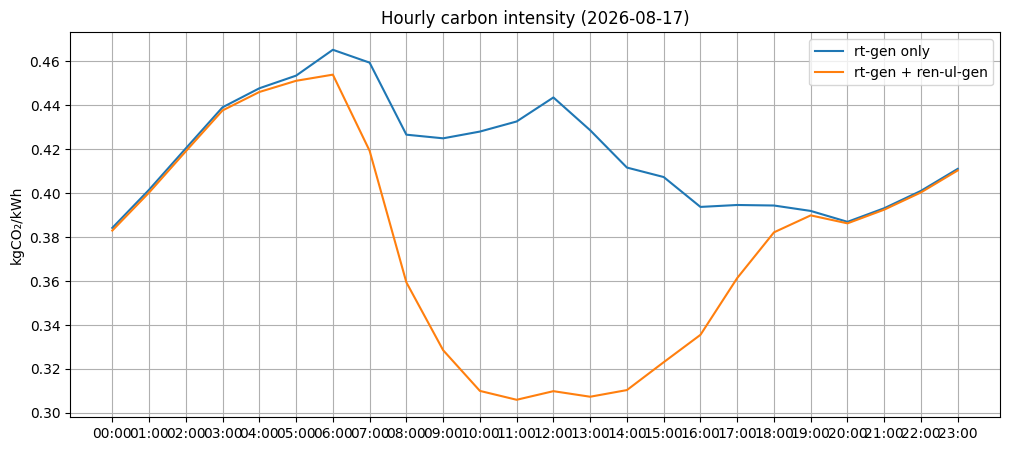

In [24]:
gen["carbon_ul"] = emission_t / (generation_mwh + ul_gen["toplam"].values)

plt.figure(figsize=(12, 5))
plt.plot(gen["hour"], gen["carbon"], label="rt-gen only")
plt.plot(gen["hour"], gen["carbon_ul"], label="rt-gen + ren-ul-gen")
plt.ylabel("kgCO₂/kWh"); plt.title(f"Hourly carbon intensity ({DAY})")
plt.legend(); plt.grid(True); plt.show()


* *Interpretation (fill in after running):* how much does midday carbon intensity drop, and does the ranking of the cleanest hours change?

Changes in the percentage distribution of energy production by the hour (licensed `rt-gen` sources only, so the solar share is underestimated).

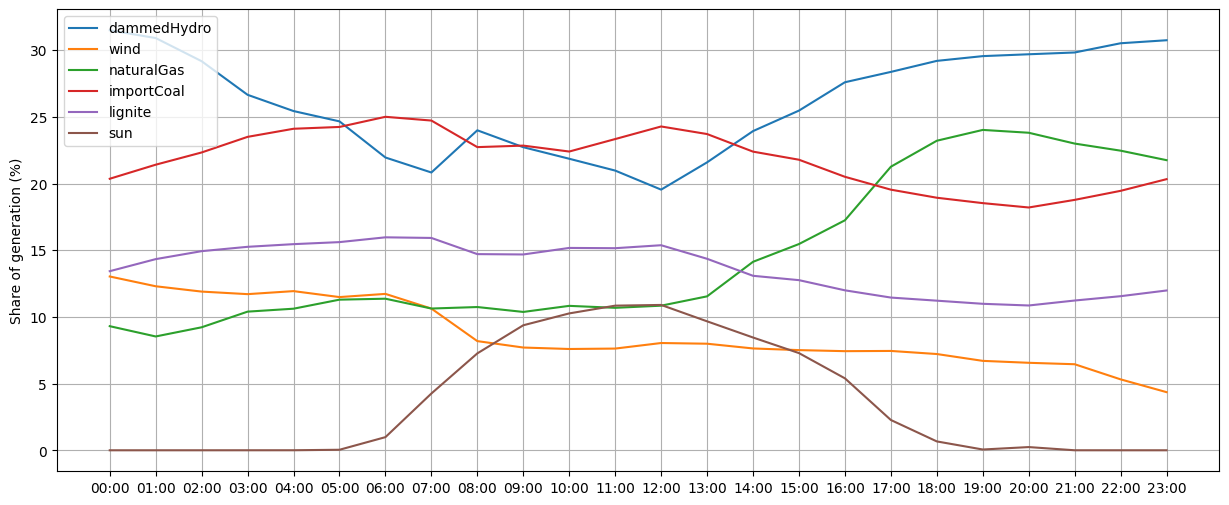

In [25]:
share = gen_sources.div(gen_sources.sum(axis=1), axis=0) * 100   # contribution of each source(%)

plt.figure(figsize=(15, 6))

for col in ["dammedHydro", "wind", "naturalGas", "importCoal", "lignite", "sun"]:
    plt.plot(gen["hour"], share[col], label=col)

plt.ylabel("Share of generation (%)"); plt.legend(); plt.grid(True); plt.show()

### Merging price and carbon

PTF and carbon intensity are combined into one table for the same day, so that each hour has both its price (TL/MWh) and its carbon intensity (kgCO₂/kWh). Before merging, the timestamps of the two tables are checked to make sure each row refers to the same hour; the `assert` stops the notebook if they do not match.

In [26]:
assert (ptf["date"] == gen["date"]).all(), "Hours do not match!"

df = pd.DataFrame({
    "hour":   gen["hour"],
    "price":  ptf["price"],          # TL/MWh
    "carbon": gen["carbon_ul"],      # kgCO2/kWh, including unlicensed generation
})

df = df.round(3)

df.head()

,hour,price,carbon
0,00:00,3584.00,0.383
1,01:00,3200.00,0.400
2,02:00,3200.00,0.419
3,03:00,3000.00,0.438
4,04:00,2799.18,0.446


### Price vs. carbon for each hour

Each point is one hour, colored by time of day (dark = night, light = midday). 

* The dashed lines are the daily median price and median carbon intensity; they split the hours into four groups. Hours in the bottom-left are cheaper and cleaner than at least half of the day. 



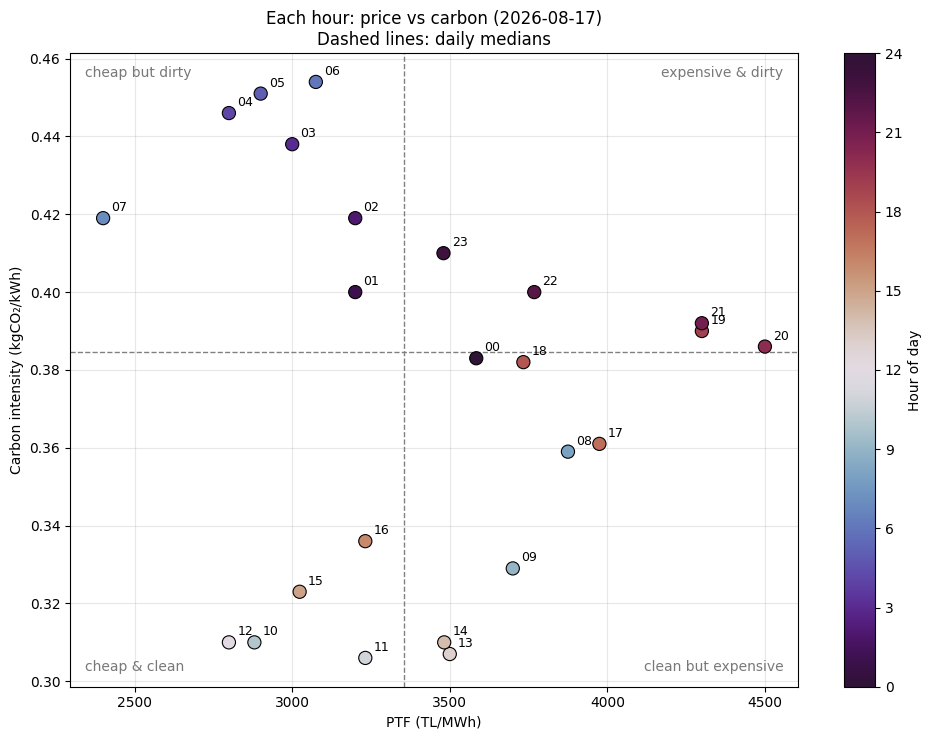

In [ ]:
import numpy as np

hours = df["hour"].str[:2].astype(int)

med_price, med_carbon = df["price"].median(), df["carbon"].median()

fig, ax = plt.subplots(figsize=(10, 7.5))

sc = ax.scatter(df["price"], df["carbon"], c=hours, cmap="twilight_shifted",
                vmin=0, vmax=24, s=90, edgecolors="black", linewidths=0.8, zorder=3)
for x, y, h in zip(df["price"], df["carbon"], hours):
    ax.annotate(f"{h:02d}", (x, y), textcoords="offset points", xytext=(6, 5), fontsize=9)

# Median lines
ax.axvline(med_price, color="gray", linestyle="--", linewidth=1)
ax.axhline(med_carbon, color="gray", linestyle="--", linewidth=1)

# Areas
kw = dict(transform=ax.transAxes, fontsize=10, color="dimgray", alpha=0.9)
ax.text(0.02, 0.02, "cheap & clean", ha="left", va="bottom", **kw)
ax.text(0.02, 0.98, "cheap but dirty", ha="left", va="top", **kw)
ax.text(0.98, 0.02, "clean but expensive", ha="right", va="bottom", **kw)
ax.text(0.98, 0.98, "expensive & dirty", ha="right", va="top", **kw)

cbar = fig.colorbar(sc, ax=ax, ticks=range(0, 25, 3))
cbar.set_label("Hour of day")

ax.set_xlabel("PTF (TL/MWh)")
ax.set_ylabel("Carbon intensity (kgCO₂/kWh)")
ax.set_title(f"Each hour: price vs carbon ({DAY})\nDashed lines: daily medians")
ax.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

**References**
1. T.C. Enerji ve Tabii Kaynaklar Bakanlığı, *Türkiye Elektrik Üretimi ve Elektrik Tüketim Noktası Emisyon Faktörleri (2023)*, 2025. https://enerji.gov.tr/Media/Dizin/EVCED/tr/%C3%87evreVe%C4%B0klim/%C4%B0klimDe%C4%9Fi%C5%9Fikli%C4%9Fi/EmisyonFaktorleri/2023_Turkiye_Elektrik_UretimiveElektrik_Tuketim_Noktasi_Emisyon_Faktorleri.pdf
2. M. Akın, T. Orucu, T. Fridriksson, "Characterizing the Declining CO₂ Emissions from Turkish Geothermal Power Plants," *45th Workshop on Geothermal Reservoir Engineering*, Stanford University, 2020. https://open.metu.edu.tr/bitstream/handle/11511/87658/index.pdf
3. G. N. Bulanık Durmuş, "Carbon-Aware Load Shifting Using Real Electricity Consumption Data," *Gazi University Journal of Science Part C*, 14(2), 1156–1169, 2026.
4. T. Ulutaş, Ü. Kurt, "Decomposing Türkiye's Official Grid Emission Factor: Hourly Resolution, Publication Lag, and Limits of Reconstruction," *Electricity*, 7(4), 123, 2026. https://doi.org/10.3390/electricity7040123